<a href="https://colab.research.google.com/github/snorzah/scudem/blob/main/SCUDEM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import scipy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint


In [ ]:
## 8kg Spider Monkey (Ateles), Adult Spider Monkey

## ENVIRONMENTAL FACTORS

b = 12.0        # Daylight duration / active foraging window (hours)
v = 1.0         # Canopy travel speed (m/s) [~3.6 km/h]
k = 10          # Smoothing Factor

##  METABOLIC & ENERGETIC PARAMETERS (kJ, kJ/h)

# Basal Metabolic Rate (kJ/h) — BMR = 293 * M^0.75 / 24
# Source: White & Seymour (2003, 2005)
# - https://www.pnas.org/doi/10.1073/pnas.0436428100
# - https://pubmed.ncbi.nlm.nih.gov/15855392/

C_0 = 60.0 #kJ/h

# Locomotion Cost Coefficient (kJ / (h * (m/s)^2))
# Source: Taylor et al. (1982)
# - https://pubmed.ncbi.nlm.nih.gov/7086334/

C_v = 25.0

# Initial Energy Reserve (kJ) — ~1.5 days of daily metabolic budget

E_0 = 3000.0

# Peak Group Food Intake Rate (kJ/h)
# Source: Pontzer et al. (2014)
# - https://www.pnas.org/doi/10.1073/pnas.1316940111

I_max = 380.0


# 4. SOCIAL & TRUST PARAMETERS

alpha = 0.5     # Trust formation rate
e_0 = 0.5       # Tolerated error threshold in energy disparity
T0 = 0.5        # Initial trust level [0, 1]
Gamma_i = 0.45  # Baseline greed for monkey i
Gamma_j = 0.55  # Baseline greed for monkey j

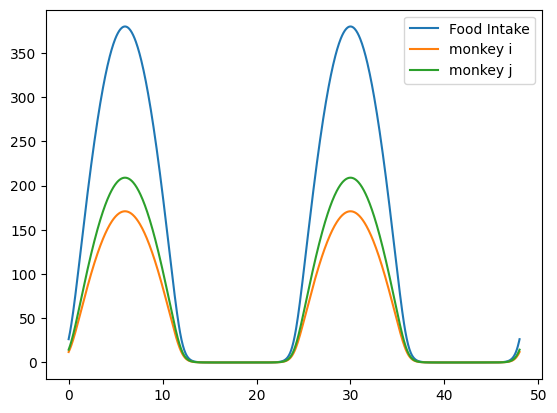

In [ ]:

t = np.linspace(0, 48, 1000)

I = lambda t: (I_max * np.log(1+np.exp(k*np.sin(np.pi * t/b)))) / np.log(1 + np.exp(k))
I_arr = I(t) # food intake rate

plt.plot(t, I_arr, label = 'Food Intake')


I_i = lambda t: 1/2 * (1+Gamma_i-Gamma_j) * I(t)
I_j = lambda t: 1/2 * (1+Gamma_j-Gamma_i) * I(t)

plt.plot(t, I_i(t), label = 'monkey i')
plt.plot(t, I_j(t), label = 'monkey j')
plt.legend()

$$\frac{dT_i}{dt}=\alpha \max(e_0-e_j(t),0) (1-T_i) - \Gamma_j(t) \max(e_j(t)-e_0, 0) T_i$$
$$\frac{dT_j}{dt}=\alpha \max(e_0-e_i(t),0) (1-T_i) - \Gamma_i(t) \max(e_i(t)-e_0, 0) T_j$$
where $$\Gamma_i(t) = -ST_j+1$$ and $$\Gamma_j(t) = -ST_i+1$$
Plugging this in, we get the system of differential equations for trust:
$$\frac{dT_i}{dt}=\alpha \max(e_0-e_j(t),0) (1-T_i) - (1-ST_i) \max(e_j(t)-e_0, 0) T_i$$
$$\frac{dT_j}{dt}=\alpha \max(e_0-e_i(t),0) (1-T_i) - (1-ST_j) \max(e_i(t)-e_0, 0) T_j$$

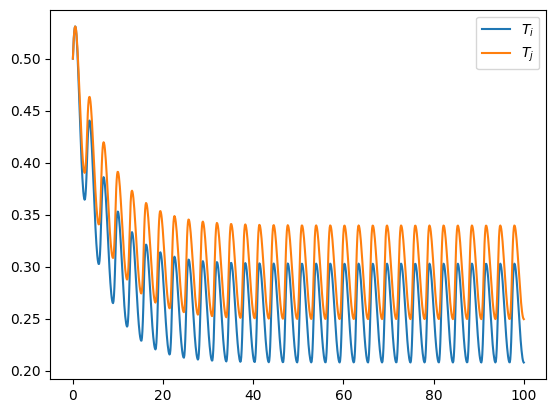

In [ ]:
e = lambda t: np.abs(np.sin(t)) # could make e_j and e_i related to E_i and E_j
def dTidt(T, t):
  return alpha * max([e_0 - e(t), 0]) * (1-T) - Gamma_j * max([e(t) - e_0, 0]) * T
def dTjdt(T, t):
  return alpha * max([e_0 - e(t), 0]) * (1-T) - Gamma_i * max([e(t) - e_0, 0]) * T
t = np.linspace(0,100,1000)
T0 = 0.5
plt.plot(t, T_i, label = "$T_i$")
plt.plot(t, T_j, label = "$T_j$")
plt.legend()

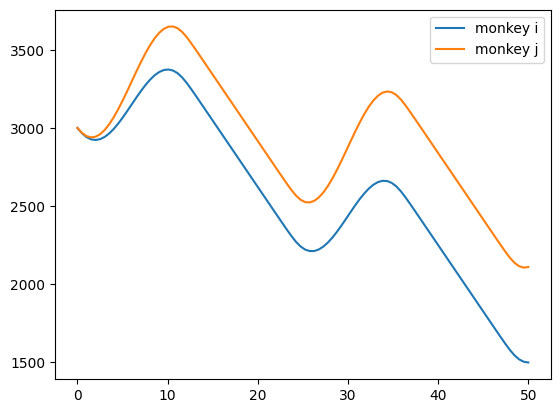

In [ ]:
def dEidt(E, t):
  return I_i(t) - ((C_v*(v**2)) + (C_0))

def dEjdt(E, t):
  return I_j(t) - ((C_v*(v**2)) + (C_0))

t = np.linspace(0,50,100)

Ei = odeint(dEidt, E_0, t)
Ej = odeint(dEjdt, E_0, t)
plt.plot(t, Ei, label = 'monkey i')
plt.plot(t, Ej, label = 'monkey j')



plt.legend()